# Analysis notebook: Work Experience and Career Adaptability

CMSE 830 midterm project. This notebook documents the data-quality checks and exploratory analysis behind the Streamlit app (`app.py`). All preparation code lives in `cis_prep.py`, so the notebook and the app show the same numbers.

The raw data are restricted and are not included in the repository. Outputs in this notebook are aggregates only. To rerun it, an authorized user places the data file at `data/cis.csv` (see the README).

In [1]:
# Setup: imports and data
import sys
from pathlib import Path

# Make cis_prep importable whether the notebook runs from notebooks/ or the repo root
for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "cis_prep.py").exists():
        sys.path.insert(0, str(folder))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

import cis_prep as cp

cp.set_plot_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

raw = cp.load_raw()          # all waves, all campuses, text columns
t1 = cp.build_analytic(raw)  # T1, four-year campuses, analysis columns only

# Raw T1 rows for the same campuses (used only for ID and income checks;
# no campus names or individual records are printed from this frame)
t1_raw = raw.loc[(raw["survey_time"] == cp.WAVE)
                 & (raw["institution_type"] != "Technical College")]

## 1. Data source and observation unit

The data come from the College Internship Study (CIS), a three-wave longitudinal survey of college students conducted by the Center for Research on College-Workforce Transitions (CCWT) at UW-Madison. The data are de-identified and restricted, so the repository includes data-access instructions rather than the data. The raw file stacks all waves, so one row is one student's response at one wave (5,747 rows, 278 columns). I keep wave one (T1) and drop the two technical colleges, which leaves 2,995 students at 11 four-year campuses (HBCU 1,468, HSI 562, four-year public 965). In the analytic sample, one row is one student (2,995 rows, 44 columns), and there are no duplicate student IDs. No data integration is needed at this stage.

In [2]:
# Data source and observation unit
print("Raw file (all waves, 13 campuses):", raw.shape)
print("Analytic sample (T1, four-year campuses):", t1.shape)

# How the stacked file breaks down by wave and institution type
display(pd.crosstab(raw["institution_type"].map(cp.INST_TYPE_LABELS),
                    raw["survey_time"], margins=True, margins_name="Total"))

# One row should be one student at T1
print("Duplicate T1 student IDs:", t1_raw["t1_passcode"].duplicated().sum())
t1.info()  # structure only; no individual records are printed

Raw file (all waves, 13 campuses): (5747, 278)
Analytic sample (T1, four-year campuses): (2995, 44)


survey_time,t1,t2,t3,Total
institution_type,,,,
Four-year public,965,477,151,1593
HBCU,1468,274,152,1894
HSI,562,287,139,988
Technical college,813,347,112,1272
Total,3808,1385,554,5747


Duplicate T1 student IDs: 0
<class 'pandas.DataFrame'>
RangeIndex: 2995 entries, 0 to 2994
Data columns (total 44 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   campus                   2995 non-null   str     
 1   inst_type                2995 non-null   category
 2   field                    2994 non-null   str     
 3   first_gen                2990 non-null   str     
 4   gender                   2994 non-null   str     
 5   race                     2993 non-null   str     
 6   work_form                2990 non-null   category
 7   q12_internship           2995 non-null   str     
 8   q12_coop                 2991 non-null   str     
 9   q12_apprenticeship       2991 non-null   str     
 10  q12_practicum            2989 non-null   str     
 11  q36_job                  2995 non-null   str     
 12  q40_desired_career       2031 non-null   float64 
 13  q39_hours                2017 non-null   float

## 2. Variable and data-type audit

In [3]:
audit_notes = {
    "work_form": ("Grouping, derived", "Categorical (5 levels)",
                  "Built from q12_*, q36_job, q40 with priority rules"),
    "q40_desired_career": ("Input to work_form", "Ordinal (1-5)",
                           f"Split at {cp.ALIGN_THRESHOLD} into aligned vs unaligned"),
    "mean_alladaptability": ("Outcome", "Quantitative (1-5)", "None, stored mean"),
    "mean_concern": ("Outcome dimension", "Quantitative (1-5)", "None, stored mean"),
    "mean_control": ("Outcome dimension", "Quantitative (1-5)", "None, stored mean"),
    "mean_curiosity": ("Outcome dimension", "Quantitative (1-5)", "None, stored mean"),
    "mean_confidence": ("Outcome dimension", "Quantitative (1-5)", "None, stored mean"),
    "inst_type": ("Grouping, academic location", "Categorical (3 levels)", "Labels recoded"),
    "field": ("Grouping, academic location", "Categorical (11 levels)", "NSSE categories"),
    "first_gen": ("Grouping, background", "Binary", "Yes/No recoded to labels"),
    "gender": ("Grouping, background", "Categorical", "None"),
}

audit = pd.DataFrame([
    {"variable": var, "role": role, "kind": kind, "dtype": str(t1[var].dtype),
     "n_missing": int(t1[var].isna().sum()), "n_unique": int(t1[var].nunique()),
     "transformation": transform}
    for var, (role, kind, transform) in audit_notes.items()
])
display(audit)

,variable,role,kind,dtype,n_missing,n_unique,transformation
0,work_form,"Grouping, derived",Categorical (5 levels),category,5,5,"Built from q12_*, q36_job, q40 with priority r..."
1,q40_desired_career,Input to work_form,Ordinal (1-5),float64,964,5,Split at 4 into aligned vs unaligned
2,mean_alladaptability,Outcome,Quantitative (1-5),float64,0,88,"None, stored mean"
3,mean_concern,Outcome dimension,Quantitative (1-5),float64,0,27,"None, stored mean"
4,mean_control,Outcome dimension,Quantitative (1-5),float64,0,25,"None, stored mean"
5,mean_curiosity,Outcome dimension,Quantitative (1-5),float64,0,25,"None, stored mean"
6,mean_confidence,Outcome dimension,Quantitative (1-5),float64,0,25,"None, stored mean"
7,inst_type,"Grouping, academic location",Categorical (3 levels),category,0,3,Labels recoded
8,field,"Grouping, academic location",Categorical (11 levels),str,1,11,NSSE categories
9,first_gen,"Grouping, background",Binary,str,5,2,Yes/No recoded to labels


## 3. Data-quality evidence

### 3.1 Missing values in key variables

In [4]:
# df["category"].value_counts()

missing = t1[list(audit_notes)].isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(t1) * 100).round(2)
display(missing.sort_values("n_missing", ascending=False))

,n_missing,pct
q40_desired_career,964,32.19
work_form,5,0.17
first_gen,5,0.17
gender,1,0.03
field,1,0.03
mean_alladaptability,0,0.00
mean_concern,0,0.00
mean_confidence,0,0.00
mean_curiosity,0,0.00
mean_control,0,0.00


### 3.2 Range, plausibility, skip-logic, and scale-score checks

In [5]:
# Range, plausibility, and skip-logic checks
job = t1["q36_job"].eq("Yes")
checks = pd.DataFrame({
    "check": [
        "CAAS item outside 1-5",
        "CAAS scale mean outside 1-5",
        "Age under 17 or over 70",
        "Weekly job hours over 60 (job holders)",
        "Job holder with no q40 answer",
        "Non-job holder with a q40 answer (skip-logic violation)",
        "No classifiable work form",
    ],
    "n_flagged": [
        int(((t1[cp.ALL_ITEMS] < 1) | (t1[cp.ALL_ITEMS] > 5)).any(axis=1).sum()),
        int(((t1[list(cp.CAAS_LABELS)] < 1) | (t1[list(cp.CAAS_LABELS)] > 5)).any(axis=1).sum()),
        int(((t1["age"] < 17) | (t1["age"] > 70)).sum()),
        int((job & (t1["q39_hours"] > 60)).sum()),
        int((job & t1["q40_desired_career"].isna()).sum()),
        int((~job & t1["q40_desired_career"].notna()).sum()),
        int(t1["work_form"].isna().sum()),
    ],
})
display(checks)
display(t1[["age", "q39_hours"]].describe().round(1))

# Do the stored CAAS scale means match their items?
recomputed = pd.DataFrame({scale: t1[items].mean(axis=1)
                           for scale, items in cp.CAAS_ITEMS.items()})
recomputed["mean_alladaptability"] = recomputed[list(cp.CAAS_ITEMS)].mean(axis=1)
abs_diff = (t1[recomputed.columns] - recomputed).abs()
display(abs_diff.agg(["max", "mean"]).round(4))  # stored values are rounded to 2 decimals

,check,n_flagged
0,CAAS item outside 1-5,0
1,CAAS scale mean outside 1-5,0
2,Age under 17 or over 70,1
3,Weekly job hours over 60 (job holders),34
4,Job holder with no q40 answer,8
5,Non-job holder with a q40 answer (skip-logic v...,0
6,No classifiable work form,5


,age,q39_hours
count,2965.0,2017.0
mean,25.5,27.7
std,7.5,14.1
min,18.0,0.0
25%,21.0,19.0
50%,23.0,25.0
75%,26.0,40.0
max,73.0,100.0


,mean_concern,mean_control,mean_curiosity,mean_confidence,mean_alladaptability
max,0.0033,0.0033,0.0033,0.0033,0.0617
mean,0.0018,0.0019,0.0019,0.0018,0.0024


### 3.3 Inconsistent categories and labels

In [6]:
# Inconsistent categories and labels
# Semester labels as written in the original file (load_raw lowercases them)
semester_original = pd.read_csv(cp.DATA_PATH, encoding="latin-1",
                                usecols=["survey_semester"])["survey_semester"]
display(semester_original.value_counts())

# Race labels at T1 before the RACE_FIXES recode
display(t1_raw["q53_race_survey"].value_counts(dropna=False))

# Parents' income: answer categories by data-collection round
round_label = t1_raw["survey_year"] + " " + t1_raw["survey_semester"]
display(pd.crosstab(t1_raw["q43_parents_inc"].fillna("Missing"), round_label))

survey_semester
spring    2860
Spring    1218
fall       948
Fall       721
Name: count, dtype: int64

q53_race_survey
Black or African American              1365
White or Caucasian                      842
Hispanic or Latino                      471
Asian or Asian-American                 130
Two or more races/ethnicities            92
Other                                    38
International                            29
American Indian or Alaska Native         21
Native Hawaiian or Pacific Islander       4
NaN                                       2
Black, African American.                  1
Name: count, dtype: int64

col_0,2018 spring,2019 fall,2019 spring,2020 spring
q43_parents_inc,,,,
"$0-$19,999",0,192,0,104
"$100,000 - $124,999",81,0,50,0
"$100,000-$119,999",0,50,0,75
"$120,000-$139,999",0,19,0,56
"$125,000 - $149,999",35,0,35,0
"$140,000-$159,999",0,18,0,31
"$150,000 - $199,999",21,0,29,0
"$160,000-$179,999",0,16,0,29
"$180,000-$199,999",0,5,0,17


### 3.4 Group sizes

In [7]:
# Group sizes (imbalance across work forms and cells)
form_counts = t1["work_form"].value_counts(dropna=False).to_frame("n")
form_counts["pct"] = (form_counts["n"] / len(t1) * 100).round(1)
display(form_counts)
display(pd.crosstab(t1["work_form"], t1["inst_type"], margins=True, margins_name="Total"))

,n,pct
work_form,,
Internship,973,32.5
Unaligned job,827,27.6
No work experience,515,17.2
Career-aligned job,479,16.0
Other WBL,196,6.5
NaN,5,0.2


inst_type,HBCU,HSI,Four-year public,Total
work_form,,,,
Internship,530,140,303,973
Other WBL,118,34,44,196
Career-aligned job,178,100,201,479
Unaligned job,328,204,295,827
No work experience,309,84,122,515
Total,1463,562,965,2990


### 3.5 Sensitivity of the work-form definition to the alignment cutoff

In [8]:
# Decision check: how much does the alignment threshold matter?
rows = []
for threshold in (3, 4, 5):
    form = cp.classify_work_form(t1, align_threshold=threshold)
    for f in ["Career-aligned job", "Unaligned job"]:
        scores = t1.loc[form == f, "mean_alladaptability"]
        rows.append({"threshold": threshold, "work_form": f,
                     "n": len(scores), "mean_adaptability": scores.mean()})
display(pd.DataFrame(rows).round(3))

,threshold,work_form,n,mean_adaptability
0,3,Career-aligned job,861,3.841
1,3,Unaligned job,445,3.683
2,4,Career-aligned job,479,3.881
3,4,Unaligned job,827,3.733
4,5,Career-aligned job,194,4.024
5,5,Unaligned job,1112,3.746


### Data-quality decisions

1. Work-form classification: I assign each student to one of five mutually exclusive forms using a priority order (internship, other WBL, career-aligned job, unaligned job, no work experience). A job counts as career-aligned when the student rated it 4 or 5, meaning it builds skills for their desired career "very well" or "extremely well." The cutoff could matter. The aligned group has 861, 479, or 194 students at cutoffs of 3, 4, or 5. I chose 4 so that "somewhat well" does not count as aligned.
2. Labels and unusable variables: I standardized semester labels and merged one variant race label. I don't use parents' income in the midterm because collection rounds used two different answer scales whose income ranges do not line up. I kept the 34 job holders reporting more than 60 weekly hours and the one 73-year-old respondent, since these values are plausible and do not enter the main comparisons.

## 4. Missingness decision

(B) I use complete-case analysis. Most missing values on job alignment (q40) are structural. Among 964 missing values, 956 belong to students without a job, who were never asked the question. Only 8 job holders skipped it. As a result, 5 students (0.17%) cannot be assigned a work form, and I exclude them. Six students skipped at least one career adaptability item. Their scale scores average the items they answered, which is how the stored scores were built. Imputation would add modeling assumptions to fix a problem that affects fewer than 0.2% of students, so complete-case analysis is defensible here.

In [9]:
# Missingness evidence for the imputation decision
# Structural (skip-logic) missingness versus item nonresponse
display(pd.crosstab(t1["q36_job"].fillna("Missing"),
                    t1["q40_desired_career"].isna().map({True: "q40 missing",
                                                          False: "q40 answered"})))
# Item-level CAAS nonresponse (stored means average the items that were answered)
item_missing = t1[cp.ALL_ITEMS].isna().sum()
print("Students with at least one missing CAAS item:",
      int(t1[cp.ALL_ITEMS].isna().any(axis=1).sum()))
display(item_missing[item_missing > 0])

q40_desired_career,q40 answered,q40 missing
q36_job,,
No,0,956
Yes,2031,8


Students with at least one missing CAAS item: 6


q6_ca05_planning          1
q6_ca06_concerned         3
q7_ca08_decisions         2
q7_ca09_responsibility    2
q7_ca10_beliefs           2
q7_ca11_count_on_me       1
q8_ca14_looking           1
q8_ca16_observing         1
dtype: int64

## 5. Question 1. Do students at HBCUs, HSIs, and four-year public institutions hold different forms of work experience?

work_form,Internship,Other WBL,Career-aligned job,Unaligned job,No work experience
inst_type,,,,,
HBCU,36.2,8.1,12.2,22.4,21.1
HSI,24.9,6.0,17.8,36.3,14.9
Four-year public,31.4,4.6,20.8,30.6,12.6


work_form,Internship,Other WBL,Career-aligned job,Unaligned job,No work experience
inst_type,,,,,
HBCU,530,118,178,328,309
HSI,140,34,100,204,84
Four-year public,303,44,201,295,122


chi2             115.3108
dof                8.0000
p_value            0.0000
cramers_v          0.1389
n               2990.0000
min_expected      36.8401
dtype: float64

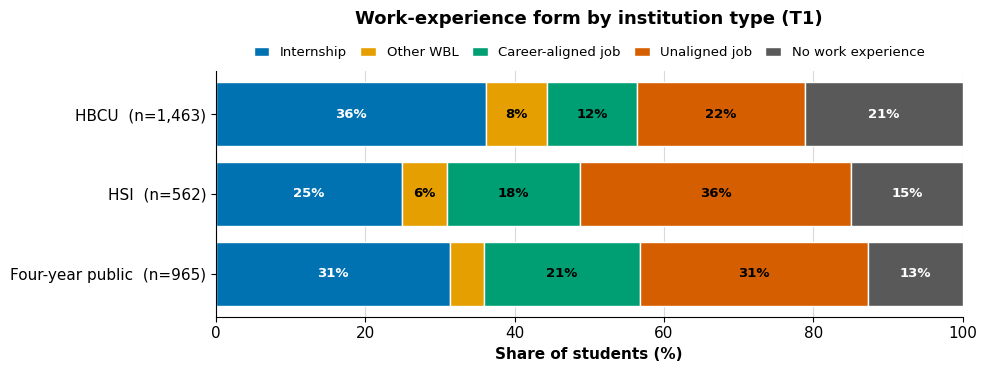

In [10]:
BY = "inst_type"
# Other options: "first_gen", "field", "gender", or a within-pairing such as
# first-generation status within institution type:
#   t1["inst_x_firstgen"] = cp.combined_group(t1, "inst_type", "first_gen")
#   BY = "inst_x_firstgen"

shares, counts = cp.form_shares(t1, BY)
display(shares.round(1))
display(counts)
display(pd.Series(cp.chi_square_test(counts)).round(4))

fig = cp.plot_form_shares(
    t1, by=BY,
    title=f"Work-experience form by {cp.GROUP_LABELS.get(BY, BY).lower()} (T1)")
plt.show()

**Interpretation and limitation.** The mix of work experience differs by institution type. HBCU students report the highest internship share (36.2%) but also the highest share with no work experience (21.1%). HSI students are the least likely to hold an internship (24.9%) and the most likely to hold a job unrelated to their career goals (36.3%). The association is statistically clear but modest in size (chi-square = 115.3, df = 8, p < .001, Cramer's V = 0.14), so institution type shifts the mix rather than determining it. For career services, this suggests different priorities by context, such as expanding internship access at HSIs, where many students already work but mostly in jobs unrelated to their goals. Limitation is institution type overlaps with when each campus was surveyed. All 884 students surveyed in spring 2020, when the pandemic disrupted internships, attend HBCUs, which is 60% of the HBCU sample.

## 6. Question 2. Does career adaptability differ across forms of work experience?

,work_form,n,mean,sd,se,ci_low,ci_high
0,Internship,973,3.880,0.666,0.021,3.838,3.922
1,Other WBL,196,3.914,0.630,0.045,3.826,4.003
2,Career-aligned job,479,3.881,0.654,0.030,3.822,3.940
3,Unaligned job,827,3.733,0.672,0.023,3.687,3.779
4,No work experience,515,3.760,0.715,0.032,3.698,3.822


anova_F       8.3942
anova_p       0.0000
kruskal_H    33.9962
kruskal_p     0.0000
dtype: float64

,work_form,n,mean_diff,cohens_d
0,Internship,973,0.120,0.175
1,Other WBL,196,0.155,0.223
2,Career-aligned job,479,0.121,0.177
3,Unaligned job,827,-0.027,-0.039


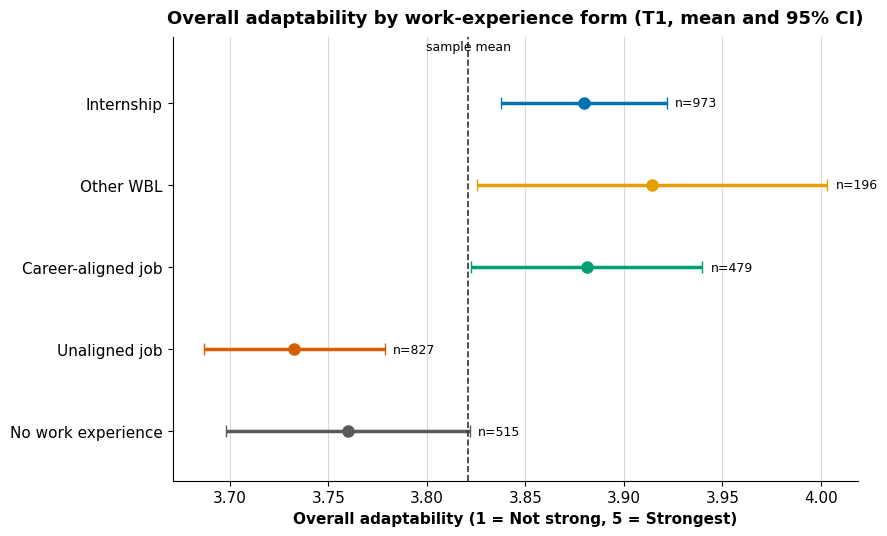

,Overall adaptability,Concern,Control,Curiosity,Confidence
work_form,,,,,
Internship,3.88,3.97,3.86,3.78,3.90
Other WBL,3.91,4.03,3.92,3.81,3.89
Career-aligned job,3.88,3.92,3.95,3.72,3.94
Unaligned job,3.73,3.78,3.81,3.57,3.77
No work experience,3.76,3.81,3.84,3.61,3.79


In [11]:
# Question 2: career adaptability across work forms
OUTCOME = "mean_alladaptability"   # or mean_concern, mean_control, ...
GROUP = None                       # or "inst_type", "first_gen"
XLIM = None                        # None zooms to the data; (1, 5) shows the full scale

display(cp.caas_summary(t1, OUTCOME, group=GROUP).round(3))
display(pd.Series(cp.compare_forms(t1, OUTCOME)).round(4))
display(cp.cohens_d_vs_reference(t1, OUTCOME).round(3))

fig = cp.plot_caas_by_form(
    t1, OUTCOME, group=GROUP, xlim=XLIM,
    title=f"{cp.CAAS_LABELS[OUTCOME]} by work-experience form (T1, mean and 95% CI)")
plt.show()

# All four dimensions side by side (means)
dim_means = pd.concat(
    {cp.CAAS_LABELS[c]: cp.caas_summary(t1, c).set_index("work_form")["mean"]
     for c in cp.CAAS_LABELS}, axis=1)
display(dim_means.round(2))

**Interpretation and limitation.** Career adaptability differs modestly across forms of work experience. Students with an internship, other WBL, or a career-aligned job score higher on average (3.88-3.91 on a 1-5 scale) than students with an unaligned job (3.73) or no work experience (3.76). The differences are statistically reliable (ANOVA F = 8.39, p < .001) but small, with Cohen's d of about 0.2 relative to students with no work experience. Students in unaligned jobs score about the same as students with no work experience (d = -0.04). However, these are cross-sectional comparisons, so they cannot separate the effect of work experience from selection into it. Students who are already more adaptable may be more likely to seek internships or career-aligned jobs.

## 7. Supporting checks

### 7.1 Distribution of adaptability scores

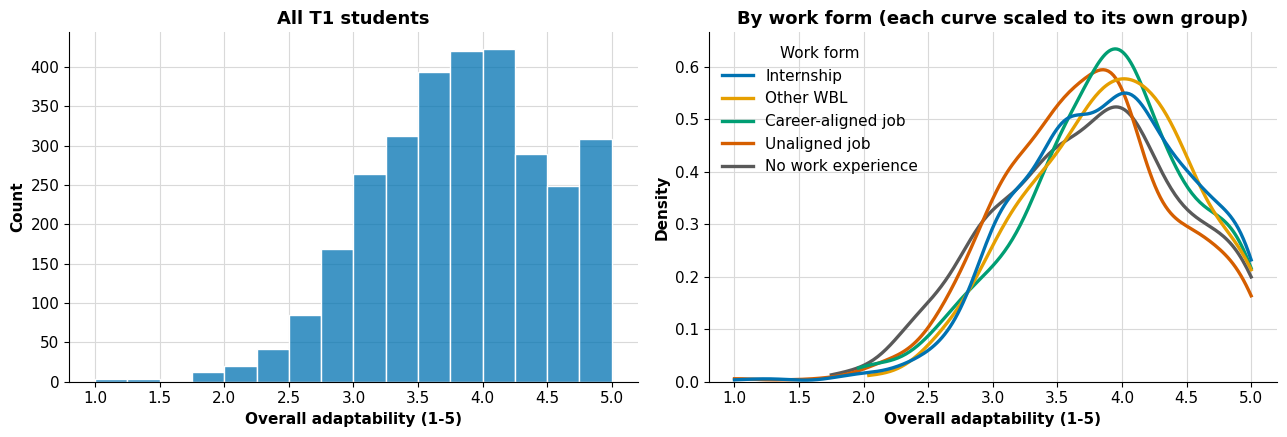

,n,mean,median,sd,skew,pct_at_max
work_form,,,,,,
Internship,973,3.88,3.92,0.67,-0.38,4.32
Other WBL,196,3.91,3.96,0.63,-0.23,3.06
Career-aligned job,479,3.88,3.92,0.65,-0.37,4.59
Unaligned job,827,3.73,3.75,0.67,-0.25,2.66
No work experience,515,3.76,3.79,0.72,-0.18,3.69


In [12]:
# Distribution / histogram / KDE
OUTCOME = "mean_alladaptability"
classified = t1.dropna(subset=["work_form"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=t1, x=OUTCOME, bins=np.linspace(1, 5, 17),  # 0.25-wide bins
             color="#0072B2", edgecolor="white", ax=axes[0])
axes[0].set_title("All T1 students")
sns.kdeplot(data=classified, x=OUTCOME, hue="work_form", hue_order=cp.FORM_ORDER,
            palette=cp.FORM_COLORS, common_norm=False, cut=0, linewidth=2.4, ax=axes[1])
axes[1].set_title("By work form (each curve scaled to its own group)")
sns.move_legend(axes[1], "upper left", title="Work form")
for ax in axes:
    ax.set_xlabel(f"{cp.CAAS_LABELS[OUTCOME]} (1-5)")
fig.tight_layout()
plt.show()

shape = classified.groupby("work_form", observed=True)[OUTCOME].agg(
    n="count", mean="mean", median="median", sd="std",
    skew=lambda s: s.skew(),
    pct_at_max=lambda s: (s == 5).mean() * 100)
display(shape.round(2))

**Decision.** Question 2 compares means of a bounded 1-5 score. Strong skewness would make means and t-based intervals misleading. My evidence is that the scores are mildly left-skewed in every group (skewness -0.18 to -0.38). Few students sit at the maximum (2.7%-4.6%). Means and medians differ by 0.05 or less. The KDE curves have similar shapes, with the unaligned-job and no-work-experience groups shifted slightly left. From this, the distributions are close enough to symmetric, and similar enough across groups, that means summarize them well. Therefore, this supports reporting means with 95% intervals. I still report the Kruskal-Wallis test alongside ANOVA, and the two agree.

### 7.2 Correlation among dimensions and with job alignment

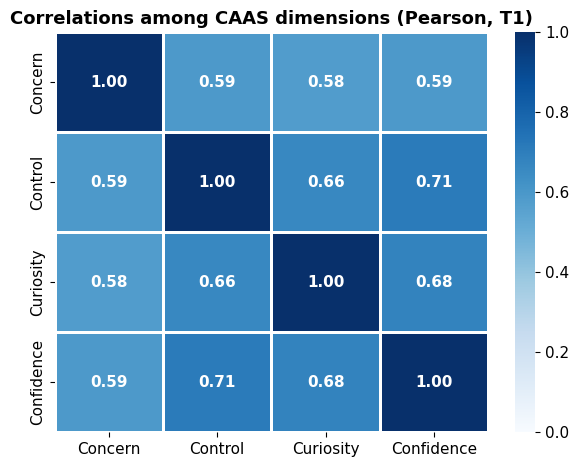

,Concern,Control,Curiosity,Confidence
Concern,1.00,0.59,0.58,0.58
Control,0.59,1.00,0.66,0.71
Curiosity,0.58,0.66,1.00,0.67
Confidence,0.58,0.71,0.67,1.00


Spearman rho (q40 vs overall adaptability, job holders) = 0.174, p = 2.833e-15


,count,mean
q40_desired_career,,
1.0,261,3.721
2.0,387,3.697
3.0,583,3.804
4.0,460,3.857
5.0,340,4.082


In [13]:
# Covariance / correlation
dims = list(cp.CAAS_ITEMS)
labels = {c: cp.CAAS_LABELS[c] for c in dims}
corr = t1[dims].corr(method="pearson").rename(index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues",
            annot_kws={"weight": "bold"}, linewidths=1, linecolor="white", ax=ax)
ax.grid(False)
ax.set_title("Correlations among CAAS dimensions (Pearson, T1)")
fig.tight_layout()
plt.show()
display(t1[dims].corr(method="spearman").rename(index=labels, columns=labels).round(2))

# Does job-to-career alignment (q40) track adaptability among job holders?
job_holders = t1.loc[t1["q36_job"].eq("Yes")]
rho, p_value = stats.spearmanr(job_holders["q40_desired_career"],
                               job_holders["mean_alladaptability"], nan_policy="omit")
print(f"Spearman rho (q40 vs overall adaptability, job holders) = {rho:.3f}, p = {p_value:.4g}")
display(job_holders.groupby("q40_desired_career")["mean_alladaptability"]
        .agg(["count", "mean"]).round(3))

**Decision.** Two decisions depend on correlation. One is whether to report a single overall score or four dimensions. The other is whether job alignment relates to adaptability gradually or in a clear step, which bears on the cutoff for career-aligned jobs. The four dimensions correlate between 0.58 and 0.71. Among job holders, alignment and overall adaptability correlate weakly (Spearman rho = 0.17, p < .001). Mean adaptability is flat across alignment levels 1 and 2 (3.72 and 3.70), rises through levels 3 and 4 (3.80 and 3.86), and jumps at level 5 (4.08). From this finding, the dimensions are related but not redundant, so the overall score works as a headline, with the dimensions available in the app. The relation with alignment is gradual, with the largest step between levels 4 and 5 rather than at my cutoff. Therefore, i keep the overall score as the main outcome and keep the cutoff at 4 for now and note in the limitations that a cutoff at 5 would sharpen the aligned vs unaligned contrast.

## 8. Method intentionally not applied

I did not apply linear regression. A regression of adaptability on work form with controls would read like an effect estimate, but cross-sectional data cannot separate the effect of work experience from selection into it.